# 01 — Exploratory Data Analysis (EDA)
## Waste Classification AI — Phase 1

**Goal:** Verify the TrashNet dataset is complete and usable, then understand its structure
(class balance, image properties, visual characteristics) before any preprocessing or model
training begins.

This notebook only *looks* at the data — no augmentation, no splitting, no training happens here.
Reusable scanning logic lives in [`src/data/dataset_info.py`](../src/data/dataset_info.py) so it
can be reused by later phases (e.g. re-verifying `data/processed/` after splitting).


In [1]:
import sys
from pathlib import Path

# Allow importing the `src` package when running this notebook from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

from src.data.dataset_info import scan_dataset, class_distribution, imbalance_ratio, summarize
from src.utils.config import TRASHNET_DIR, FIGURES_DIR, CLASS_NAMES, RANDOM_SEED
from src.utils.seed import set_seed

set_seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset directory: {TRASHNET_DIR}")
print(f"Dataset directory exists: {TRASHNET_DIR.exists()}")


Dataset directory: C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project\data\raw\dataset-resized
Dataset directory exists: True


## 1. Dataset Verification

Before any analysis, we confirm the dataset is structurally sound:
- Does every expected class folder exist?
- How many images are in each class, and in total?
- Are any image files corrupted (fail to open)?
- What file formats, color modes, and dimensions are present?

`scan_dataset()` walks every class folder, opens each image with Pillow, and records its
metadata. Files that fail to open (`UnidentifiedImageError` / `OSError`) are collected as
*corrupted* rather than crashing the scan — this matters because a single bad file in a
dataset of thousands should not block the whole pipeline; we want to know about it and
exclude it deliberately.


In [2]:
scan = scan_dataset(TRASHNET_DIR)
metadata = scan.metadata
summary = summarize(scan)

print(f"Classes found on disk : {scan.classes}")
print(f"Expected classes      : {CLASS_NAMES}")
print(f"Classes match expected: {sorted(scan.classes) == sorted(CLASS_NAMES)}")
print()
print(f"Total images scanned  : {summary['total_images']}")
print(f"Corrupted images      : {summary['num_corrupted']}")
print(f"File extensions       : {summary['extensions']}")
print(f"Color modes           : {summary['color_modes']}")
print(f"Unique (width,height) combinations: {summary['unique_dimensions']}")
print(f"Width range            : {summary['width_range']}")
print(f"Height range           : {summary['height_range']}")
print(f"Mean file size (KB)    : {summary['file_size_kb_mean']:.1f}")

if scan.corrupted_files:
    print("\nCorrupted files:")
    for f in scan.corrupted_files:
        print(" -", f)


Classes found on disk : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Expected classes      : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Classes match expected: True

Total images scanned  : 2527
Corrupted images      : 0
File extensions       : {'.jpg': 2527}
Color modes           : {'RGB': 2527}
Unique (width,height) combinations: 1
Width range            : (512, 512)
Height range           : (384, 384)
Mean file size (KB)    : 16.7


**Verification findings:**
- All 6 expected class folders are present and correctly named (`cardboard`, `glass`, `metal`,
  `paper`, `plastic`, `trash`) — no relabeling needed.
- **0 corrupted images** out of 2,527 — every file opens cleanly with Pillow.
- Every image is `.jpg`, every image is `RGB` (no grayscale/RGBA outliers to special-case).
- **Only 1 unique (width, height) pair: 512×384** for the entire dataset. This is the
  *resized* TrashNet variant — the original authors already resized everything, which is why
  we chose this version (no manual downloading of the much larger raw-image dataset needed,
  and no surprise oddly-shaped images to handle).

Because dimensions are already uniform, our preprocessing pipeline (Phase 2) doesn't need to
handle mixed aspect ratios — a straightforward `Resize` to the model's expected input size is
sufficient.


## 2. Class Distribution

Class imbalance directly affects training: a model can reach deceptively high accuracy by
mostly predicting the majority class, while the minority class gets ignored. We need to see
the imbalance now so later phases (loss weighting, stratified splitting, augmentation) can
account for it deliberately instead of by surprise.


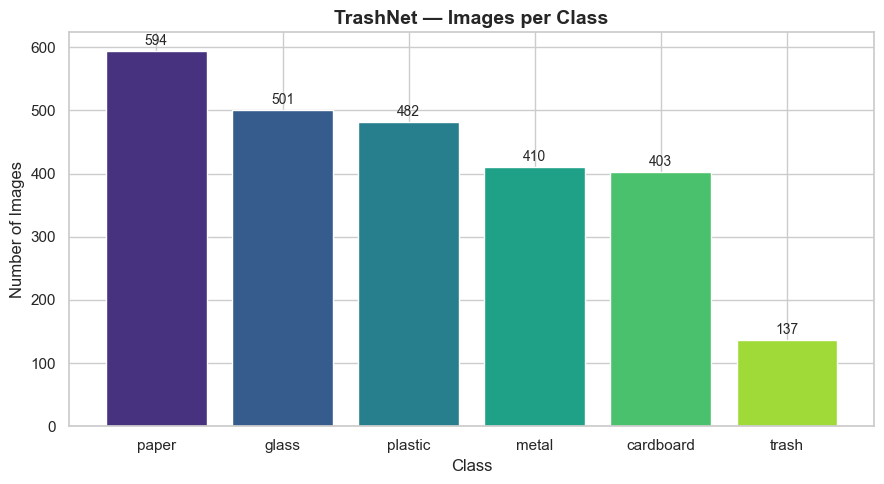

class
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137
Name: count, dtype: int64

Imbalance ratio (largest/smallest class): 4.34x


In [3]:
counts = class_distribution(metadata)
ratio = imbalance_ratio(metadata)

fig, ax = plt.subplots(figsize=(9, 5))
palette = sns.color_palette("viridis", len(counts))
bars = ax.bar(counts.index, counts.values, color=palette)
ax.set_title("TrashNet — Images per Class", fontsize=14, fontweight="bold")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(count), ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

print(counts)
print(f"\nImbalance ratio (largest/smallest class): {ratio:.2f}x")


**Class distribution findings:**
- `paper` is the largest class (594 images) and `trash` is by far the smallest (137 images) —
  an imbalance ratio of **~4.3x**.
- The other four classes (`glass`, `plastic`, `metal`, `cardboard`) sit in a moderate 400–500
  range, so the imbalance is really a **"trash is starved" problem** rather than a
  uniformly skewed dataset.
- **Implication for later phases:** a stratified train/val/test split is required (Phase 2) so
  `trash`'s already-small pool isn't further distorted by chance. During training (Phase 3+)
  we should consider class-weighted loss and keep an eye on `trash` recall specifically in
  evaluation — it's the class most likely to be under-learned.


## 3. Sample Images per Class

Numbers alone don't tell us what the model will actually see. Sampling images per class lets
us sanity-check that labels look correct, and gives an early hint about what might make
classes easy or hard to separate (background clutter, lighting, similar-looking materials).


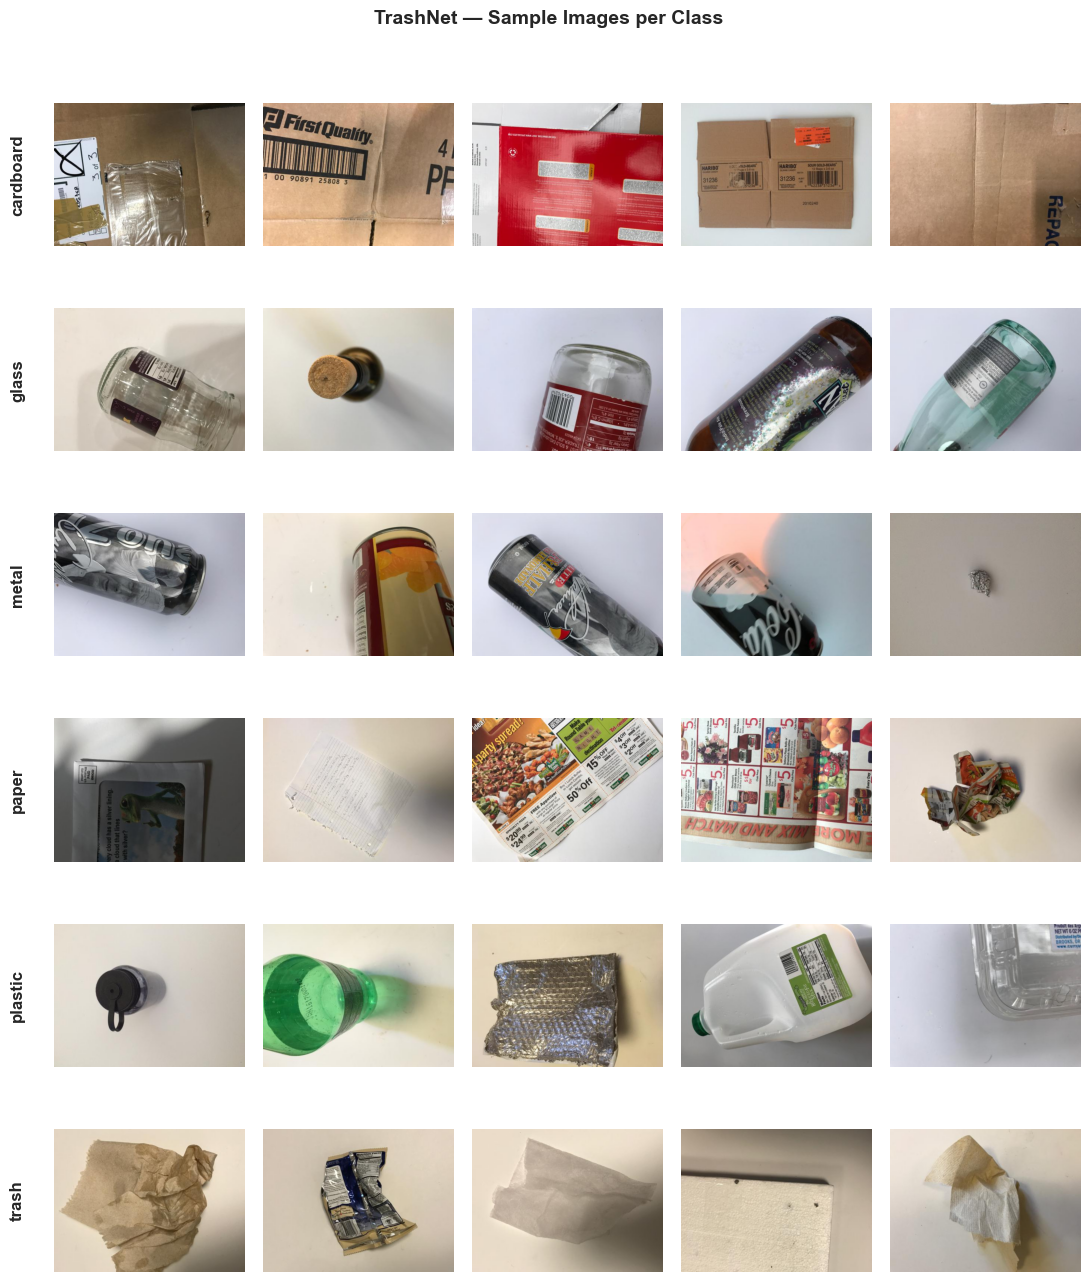

In [4]:
n_samples = 5
fig, axes = plt.subplots(len(scan.classes), n_samples, figsize=(n_samples * 2.2, len(scan.classes) * 2.2))

rng = np.random.default_rng(RANDOM_SEED)
for row, class_name in enumerate(scan.classes):
    class_paths = metadata.loc[metadata["class"] == class_name, "path"].tolist()
    sample_paths = rng.choice(class_paths, size=n_samples, replace=False)
    for col, path in enumerate(sample_paths):
        ax = axes[row, col]
        img = Image.open(path)
        ax.imshow(img)
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(class_name, fontsize=11)
            ax.text(-0.15, 0.5, class_name, transform=ax.transAxes, fontsize=12,
                    fontweight="bold", va="center", ha="right", rotation=90)

plt.suptitle("TrashNet — Sample Images per Class", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sample_images_per_class.png", dpi=150, bbox_inches="tight")
plt.show()


**Sample image findings:**
- Most images show a **single item held against a plain white/bright background** —
  a studio-style setup, not real-world clutter. This is good for a first model (less noise to
  learn through) but means the model may **not generalize well to messy, real-world photos**
  (a limitation worth stating explicitly in the final report and revisiting in Error Analysis /
  Future Improvements).
- `glass` and `plastic` (bottles/containers) look visually similar in shape — both are
  frequently clear or translucent containers — which is a plausible source of confusion the
  model may exhibit later.
- `cardboard` and `paper` can also overlap visually (both brown/beige, fibrous texture),
  another likely confusion pair to watch for in the confusion matrix.
- `trash` is a **catch-all** category (miscellaneous non-recyclable items) with no single
  consistent visual signature — combined with it having the fewest samples, this makes it the
  class most likely to be hardest for every model we train.


## 4. Image Dimensions & File Size

We already confirmed every image is exactly 512×384. This section double-checks that
visually/statistically and looks at file size, which can hint at compression artifacts or
unusually simple/complex images.


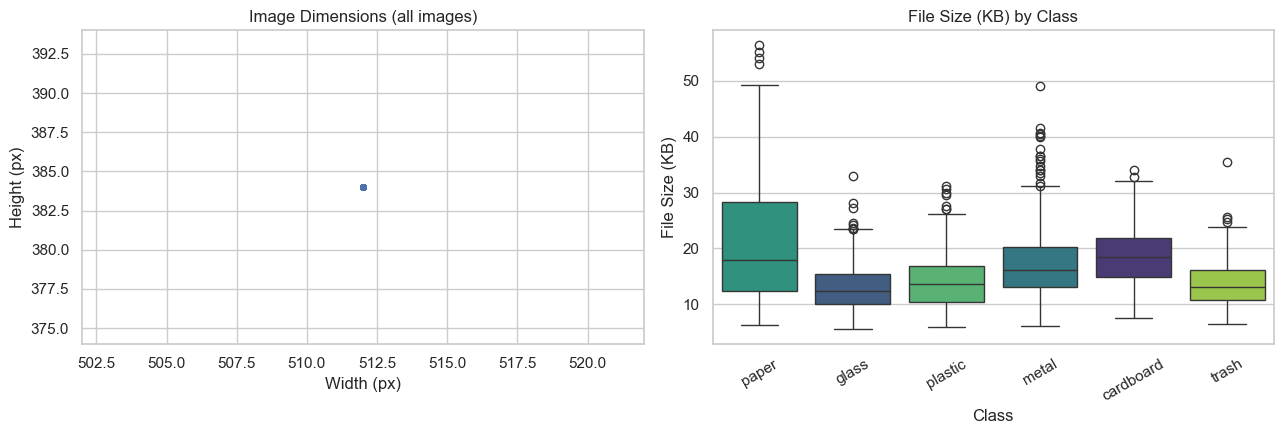

           count  mean   std  min   25%   50%   75%   max
class                                                    
cardboard  403.0  18.4   5.0  7.5  14.9  18.5  21.9  34.1
glass      501.0  13.0   4.0  5.5  10.1  12.4  15.4  33.0
metal      410.0  17.3   6.7  6.1  13.0  16.2  20.3  49.2
paper      594.0  21.1  10.5  6.3  12.4  17.9  28.3  56.5
plastic    482.0  14.1   4.7  5.8  10.4  13.6  16.9  31.2
trash      137.0  13.8   4.6  6.4  10.8  13.1  16.2  35.4


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Dimension scatter (sanity check — should collapse to a single point)
axes[0].scatter(metadata["width"], metadata["height"], alpha=0.3, s=15)
axes[0].set_title("Image Dimensions (all images)")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")
axes[0].set_xlim(metadata["width"].min() - 10, metadata["width"].max() + 10)
axes[0].set_ylim(metadata["height"].min() - 10, metadata["height"].max() + 10)

# File size distribution per class
sns.boxplot(data=metadata, x="class", y="file_size_kb", hue="class",
            order=counts.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("File Size (KB) by Class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("File Size (KB)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "dimensions_and_filesize.png", dpi=150)
plt.show()

print(metadata.groupby("class")["file_size_kb"].describe().round(1))


**Dimension & file size findings:**
- Confirmed: **all 2,527 images are exactly 512×384**, RGB — the dimension scatter is a single
  point. No resizing edge cases to handle in preprocessing.
- File sizes (JPEG compressed) mostly sit in a narrow band (~10–25 KB), consistent with simple,
  low-clutter photos. A few outliers with notably larger file size likely have more visual
  detail/texture. Nothing here suggests corrupted or degenerate files.


## 5. Summary of EDA Findings

| Aspect | Finding | Implication |
|---|---|---|
| Total images | 2,527 across 6 classes | Small dataset — favors transfer learning over training a deep CNN from scratch to reach strong accuracy, though we still build the from-scratch CNN as a baseline for comparison. |
| Corrupted images | 0 | No cleaning step required before splitting. |
| Image format | 512×384, RGB, JPEG, uniform | Preprocessing only needs a deterministic resize (e.g. to 224×224) + normalization, no format handling. |
| Class balance | Imbalanced, 4.3x (paper=594 vs trash=137) | Use a **stratified split**; consider class-weighted loss; watch `trash` recall specifically during evaluation. |
| Visual content | Clean studio backgrounds, single item per photo | Model may not generalize to cluttered real-world photos — call out as a limitation; augmentation (Phase 2) should still include realistic variation (rotation, color jitter, crop) to reduce this gap somewhat. |
| Likely confusion pairs | glass vs. plastic (containers); cardboard vs. paper (fibrous, similar tone) | Expect these pairs to show up in the confusion matrix (Phase 9 error analysis) — not a bug if they do. |

**Recommendation — proceed to Phase 2 (Data Preparation):**
1. Create a **stratified** 70/15/15 train/val/test split (fixed seed = 42) so `trash`'s small
   pool is proportionally represented in every split.
2. Define training-only augmentations (flip, rotation, color jitter, resized crop) and
   deterministic val/test transforms (resize + normalize only), per the project's Phase 2 spec.
3. Carry the class-imbalance finding forward into the training loop design (Phase 3) as a
   candidate for class-weighted `CrossEntropyLoss`.
